# Week 6 (10/8/2026): Supervised Regression

Weeks 4 and 5 predicted a category: is this an AI stock? This week we keep the same problem, the same data, the same AI shortlist and the same one-hot sectors, and move to regression, where the target is a number. Three questions: **what happens if you fit a straight line to a yes/no target, does the market pay more for AI stocks, and did AI stocks beat the market last year once we control for everything else?**

This week's readings set up two lessons:

* **Random walks.** In more dimensions, a random walk can wander off and never come back. The data-science version: the more features you search through, the more coincidences you find. Part 7 builds a regression that looks perfect and is pure noise.
* **Stein's paradox.** Shrinking many estimates toward a common value beats estimating each one on its own. That is exactly what ridge and lasso regression do to coefficients. Part 3 shows when it pays.

Topics today:

1. From categorization to regression: a straight line on the AI target (the linear probability model) and why logistic regression exists
2. Ordinary least squares by hand, in one picture
3. Multiple regression with a statsmodels summary: coefficients, t-statistics, p-values, R-squared, and the AI premium in valuations
4. Multicollinearity and the variance inflation factor
5. Train vs test R-squared, and leakage
6. Shrinkage: Stein's paradox, ridge (L2) and lasso (L1)
7. Last year's returns: did AI stocks win once we control for risk?
8. Linear regression in PyTorch: one neuron with a squared-error loss
9. Random walks and spurious regression, the bridge to next week's stat arb

The data is the same pair of Bloomberg files as Weeks 3 to 5. These are licensed Bloomberg PORT exports and are not included in this repository; the README describes the columns so you can follow along with your own cross-section of stocks.

In [ ]:
# Data download removed: the two Bloomberg PORT exports are licensed and not redistributed (see README).
# Place 20260917_BLG_Port.xlsx and 20260917_BLG_Port_2.xlsx in the working directory.

In [2]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, LassoCV
from sklearn.metrics import r2_score

## Load, clean and merge (same steps as Weeks 3 to 5)

Skip Bloomberg's two metadata rows, drop the rows with no Short Name (the grouping row, the blank row and the disclaimer), merge on Ticker, index by the short ticker, and rename to snake_case.

In [3]:
df1 = pd.read_excel('20260917_BLG_Port.xlsx', skiprows=2)
df2 = pd.read_excel('20260917_BLG_Port_2.xlsx', skiprows=2)
df1 = df1[df1['Short Name'].notna()]
df2 = df2[df2['Short Name'].notna()]
df = df1.merge(df2, on='Ticker', how='inner', suffixes=('_f1', '_f2'), validate='one_to_one')
df['Ticker'] = df['Ticker'].map(lambda s: s.split()[0])
df = df.set_index('Ticker')
df.shape

(1600, 79)

In [4]:
column_mapping = {
    "Short Name_f1": "short_name_1",
    "Ticker.1_f1": "ticker_1",
    "PORT US Prof Fact Exp:D-1": "port_us_profitability",
    "PORT US Vol Fact Exp:D-1": "port_us_volatility",
    "PORT US Lev Fact Exp:D-1": "port_us_leverage",
    "PORT US Mom Fact Exp:D-1": "port_us_momentum",
    "PORT US Val Fact Exp:D-1": "port_us_value",
    "PORT US Gr Fact Exp:D-1": "port_us_growth",
    "PORT US Dvd Yld Fact Exp:D-1": "port_us_dividend_yield",
    "PORT US Earn Var Fact Exp:D-1": "port_us_earnings_variability",
    "P/S": "price_to_sales",
    "BEst P/S BF12M": "est_price_to_sales_fwd12m",
    "P/B": "price_to_book",
    "BEst P/B BF12M": "est_price_to_book_fwd12m",
    "P/E": "price_to_earnings",
    "BEst P/E BF12M": "est_price_to_earnings_fwd12m",
    "ROE LF": "roe_last_fiscal",
    "GICS SubInd": "gics_sub_industry",
    "GICS Sector": "gics_sector",
    "GICS Ind Name": "gics_industry_name",
    "GICS SubInd Name": "gics_sub_industry_name",
    "ESG Disclosure Score (Latest Available)": "esg_disclosure_score",
    "Beta:Y-1": "beta_1y",
    "Total Return:Y-1": "total_return_1y",
    "Number of Employees:Y": "num_employees",
    "Number of Employees:Y-5": "num_employees_5y_ago",
    "Market Cap": "market_cap",
    "Total Return:M-3": "total_return_3m",
    "Gr PoP of Tot Debt:Q:Q[currency=LCL], -12)": "total_debt_growth_qoq_12m",
    "Insider Sells Volume 1 Year:Y-1": "insider_sells_volume_1y",
    "FCF Yld": "fcf_yield",
    "FCF Yld:Q-12": "fcf_yield_q_12m",
    "Net Fixed Asset Turnover LF": "net_fixed_asset_turnover_lf",
    "PORT US Sz Fact Exp:D-1": "port_us_size",
    "Gr PoP of Net Fixed Asset Turnover:Y:Y, -5)": "net_fixed_asset_turnover_growth_5y",
    "Equity Traded Val:D-1_f1": "equity_traded_value_1d",
    "Rank(Equity Traded Val 1 Day ago)_f1": "equity_traded_value_rank_1d",
    "CUSIP": "cusip",
    "FCF Yld:Y": "fcf_yield_y",
    "FCF Yld:Y-1": "fcf_yield_y_1",
    "Short Name_f2": "short_name_2",
    "Equity Traded Val:D-1_f2": "equity_traded_value_1d_2",
    "Rank(Equity Traded Val 1 Day ago)_f2": "equity_traded_value_rank_1d_2",
    "Ticker.1_f2": "ticker_2",
    "Avg Px Pd Repurch LF": "avg_price_paid_repurchase_lf",
    "Val Sh Repurch fr Repurch Prog:Y": "value_shares_repurchased_y",
    "Val Sh Repurch fr Repurch Prog:Y-1": "value_shares_repurchased_y_1",
    "Shares Out:Y": "shares_outstanding",
    "Shares Out:Y-1": "shares_outstanding_y_1",
    "BEst CAPEX BF12M": "est_capex_fwd12m",
    "BEst CAPEX:CQ-4 BF12M": "est_capex_cq4_fwd12m",
    "Energy Intensity per Sales (Latest Available) (BLOOMBERG L.P.)": "energy_intensity_per_sales",
    "Engy Intens/Empl:Y": "energy_intensity_per_employee",
    "Engy Intens/EBITDA:Y": "energy_intensity_per_ebitda",
    "BI STOX Quality (BLOOMBERG L.P.)": "bi_stox_quality",
    "BI STOX Leverage (BLOOMBERG L.P.)": "bi_stox_leverage",
    "BI STOX Low Volatility (BLOOMBERG L.P.)": "bi_stox_low_volatility",
    "BI STOX Profitability (BLOOMBERG L.P.)": "bi_stox_profitability",
    "BI STOX Multi-Factor Score (BLOOMBERG L.P.)": "bi_stox_multi_factor_score",
    "Bloomberg Issuer Likelihood of Default (Adjusted)": "bbg_issuer_default_likelihood",
    "Bloomberg Issuer Default Risk Implied CDS Spread (Adjusted)": "bbg_issuer_default_risk_cds",
    "BI STOX Momentum (BLOOMBERG L.P.)": "bi_stox_momentum",
    "PORT MAC3 Lqdty Factor Exp:D-1": "port_mac3_liquidity",
    "PORT MAC3 Dvd Yld Factor Exp:D-1": "port_mac3_dividend_yield",
    "PORT MAC3 Value Factor Exp:D-1": "port_mac3_value",
    "PORT MAC3 Beta Factor Exp:D-1": "port_mac3_beta",
    "PORT MAC3 Prof Factor Exp:D-1": "port_mac3_profitability",
    "PORT MAC3 Vol Factor Exp:D-1": "port_mac3_volatility",
    "PORT MAC3 Residl Vol Factor Exp:D-1": "port_mac3_residual_volatility",
    "PORT MAC3 Var Factor Exp:D-1": "port_mac3_variability",
    "PORT MAC3 Ern Yld Factor Exp:D-1": "port_mac3_earnings_yield",
    "PORT MAC3 Gwth Factor Exp:D-1": "port_mac3_growth",
    "PORT MAC3 Qual Factor Exp:D-1": "port_mac3_quality",
    "PORT MAC3 LT Rev Factor Exp:D-1": "port_mac3_long_term_reversal",
    "PORT MAC3 Size Factor Exp:D-1": "port_mac3_size",
    "PORT MAC3 Mom Factor Exp:D-1": "port_mac3_momentum",
    "PORT MAC3 Lvrg Factor Exp:D-1": "port_mac3_leverage",
    "PORT MAC3 Mid Cap Factor Exp:D-1": "port_mac3_mid_cap",
    "PORT MAC3 Valtn Factor Exp:D-1": "port_mac3_valuation",
}

df = df.rename(columns=column_mapping)
mac3_names = list(df.filter(like='_mac3_').columns)
print(len(mac3_names), 'MAC3 factors')

17 MAC3 factors


In [5]:
sector_dummies = pd.get_dummies(df['gics_sector'], prefix='sector', drop_first=True, dtype=int)
sector_dummies.columns = sector_dummies.columns.str.lower().str.replace(' ', '_')
df = df.join(sector_dummies)
sector_names = list(sector_dummies.columns)
print(len(sector_names), 'sector dummies; the baseline is Communication Services')

10 sector dummies; the baseline is Communication Services


## The same target as Weeks 4 and 5

The AI shortlist, 1 if the ticker is on it and 0 if not, and the same stratified split.

In [6]:
ai_tickers = [
    # US-listed tickers
    "AAOI", "AAPL", "ALAB", "AMAT", "AMD", "AMZN", "ANET", "ARM",
    "ASML", "AVGO", "BABA", "BIDU", "CBRS", "COHR", "CRDO", "CRM",
    "CRWD", "CRWV", "CSCO", "DDOG", "DELL", "ETN", "FLEX", "GEV",
    "GOOGL", "HUT", "IBM", "INTC", "IREN", "KI5", "LITE", "LRCX",
    "LSCC", "MDB", "META", "MRVL", "MSFT", "MTSI", "MU", "NBIS",
    "NEE", "NET", "NFLX", "NOW", "NTNX", "NVDA", "OKLO", "ORCL",
    "PANW", "PLTR", "QCOM", "RBLX", "RIOT", "SAP", "SHOP", "SKM",
    "SMCI", "SNDK", "SNOW", "SPCX", "SSNLF", "TER", "TSEM", "TSLA",
    "TSM", "VRT", "WDC", "YNDX", "ZS",
    # Non-US listed tickers (exchange-local symbols)
    "000660", "005930", "0700", "2308", "2330", "2345", "2360",
    "2383", "2454", "2513", "3017", "3037", "3711", "402340",
    "6669", "6857", "6976", "8035", "9984"
]

df['TgtVariable'] = df.index.isin(ai_tickers) + 0
fnames = mac3_names + sector_names
train_df, test_df = train_test_split(df, test_size=0.2, random_state=5, stratify=df['TgtVariable'])
print(df['TgtVariable'].sum(), 'AI stocks of', len(df), '|', len(fnames), 'features')

65 AI stocks of 1600 | 27 features


# Part 0: From categorization to regression

What if we ignore the fact that the target is 0 or 1 and fit an ordinary straight line? This is called the **linear probability model**. It is regression's first attempt at classification, and it shows exactly why logistic regression was invented: last week's Iron Man line, a line has no idea that a probability must stay between 0 and 1.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

lpm = LinearRegression().fit(train_df[fnames], train_df['TgtVariable'])
p_lpm = lpm.predict(test_df[fnames])
logit = LogisticRegression(class_weight='balanced', max_iter=1000).fit(train_df[fnames], train_df['TgtVariable'])
p_logit = logit.predict_proba(test_df[fnames])[:, 1]

p_all = lpm.predict(df[fnames])
print(f'linear predictions range from {p_all.min():.2f} to {p_all.max():.2f}')
print(f'stocks with a predicted probability below 0: {(p_all < 0).sum()}, above 1: {(p_all > 1).sum()}')
print(f'test AUC: linear probability model {roc_auc_score(test_df["TgtVariable"], p_lpm):.3f} | logistic regression {roc_auc_score(test_df["TgtVariable"], p_logit):.3f}')

linear predictions range from -0.21 to 0.48
stocks with a predicted probability below 0: 708, above 1: 0
test AUC: linear probability model 0.979 | logistic regression 0.980


**Reading it.** The straight line ranks stocks almost as well as logistic regression: test AUC 0.979 against 0.980. But its outputs are not probabilities. They run from -0.21 to 0.48, and 708 stocks get a predicted probability below zero. A line keeps going in both directions; the sigmoid bends it into 0 to 1. Use the linear probability model to rank, never to quote a probability. From here on the targets are real numbers, where a straight line is the right tool.

# Part 1: Regression in one picture

Start with one feature. Bloomberg's MAC3 model gives each stock a **beta exposure**, a standardized score. The data also has each stock's **measured beta** over the past year. How does one translate into the other?

Ordinary least squares draws the line that minimizes the sum of squared vertical distances, Gauss's choice from last week's story because squares can be differentiated and absolute values cannot. With one feature the answer has a closed form:

* slope = covariance(x, y) / variance(x)
* intercept = mean(y) - slope x mean(x)

Three tools, one answer: the formula by hand, `np.polyfit`, and scikit-learn.

by hand:      slope 0.566, intercept 1.077
np.polyfit:   [0.566 1.077]
scikit-learn: slope 0.566, intercept 1.077
correlation 0.877, R-squared 0.769


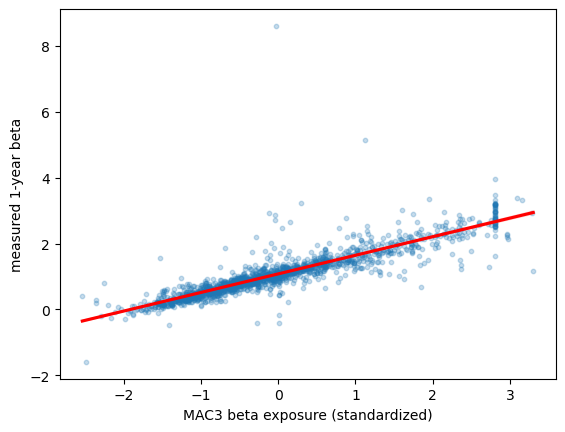

In [8]:
pair = df[['port_mac3_beta', 'beta_1y']].dropna()
x, y = pair['port_mac3_beta'], pair['beta_1y']

slope = np.cov(x, y)[0, 1] / np.var(x, ddof=1)
intercept = y.mean() - slope * x.mean()
print(f'by hand:      slope {slope:.3f}, intercept {intercept:.3f}')
print('np.polyfit:  ', np.polyfit(x, y, 1).round(3))
lr = LinearRegression().fit(pair[['port_mac3_beta']], y)
print(f'scikit-learn: slope {lr.coef_[0]:.3f}, intercept {lr.intercept_:.3f}')
print(f'correlation {x.corr(y):.3f}, R-squared {x.corr(y) ** 2:.3f}')

sns.regplot(x=x, y=y, scatter_kws={'alpha': 0.25, 's': 10}, line_kws={'color': 'red'})
plt.xlabel('MAC3 beta exposure (standardized)')
plt.ylabel('measured 1-year beta')
plt.show()

**Reading it.** Slope 0.566, intercept 1.077. A stock with an average exposure (0) has a measured beta of about 1.08, and each extra unit of exposure adds about 0.57. All three tools agree to three decimals because there is only one least-squares line. The correlation is 0.877 and R-squared is 0.769: with one feature, R-squared is just the correlation squared. The exposure explains about three quarters of the variation in measured beta; the rest is what the exposure does not capture.

# Part 2: What does the market pay for?

Now many features at once. The target is **price to sales**: what investors pay for each dollar of revenue. We use P/S rather than P/E because it exists for companies that lose money, and we take its log because P/S runs from under 1 to over 16,000. On a log scale, a coefficient of 0.1 means about 26 percent more per dollar of sales (10 to the power 0.1 is 1.26).

**Leave out the price-based factors.** MAC3's value, valuation, earnings-yield and dividend-yield factors are built from price ratios, so they contain the target. That is the same leakage as momentum and last year's return in Week 3. We keep the other 13 factors, the sector dummies, and **the AI flag** from Weeks 4 and 5: its coefficient answers whether the market pays more for an AI stock than for a similar non-AI stock in the same sector.

In [9]:
val = df[df['price_to_sales'] > 0].copy()
val['log_ps'] = np.log10(val['price_to_sales'])

price_based = ['port_mac3_value', 'port_mac3_valuation', 'port_mac3_earnings_yield', 'port_mac3_dividend_yield']
nonprice = [c for c in mac3_names if c not in price_based]
features = nonprice + sector_names + ['TgtVariable']   # the AI flag joins the regression

val_train, val_test = train_test_split(val, test_size=0.2, random_state=5)
print(len(val), 'stocks with positive P/S |', len(val_train), 'train |', len(val_test), 'test |', len(features), 'features')

1525 stocks with positive P/S | 1220 train | 305 test | 24 features


## The statsmodels summary

scikit-learn is built to predict. statsmodels is built to explain: every coefficient comes with a standard error, a t-statistic and a p-value. This is the classical, frequentist view from Week 4, where you judge significance after the fit.

In [10]:
ols = sm.OLS(val_train['log_ps'], sm.add_constant(val_train[features].astype(float))).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:                 log_ps   R-squared:                       0.425
Model:                            OLS   Adj. R-squared:                  0.414
Method:                 Least Squares   F-statistic:                     36.83
Date:                Thu, 08 Oct 2026   Prob (F-statistic):          1.67e-125
Time:                        17:32:45   Log-Likelihood:                -638.09
No. Observations:                1220   AIC:                             1326.
Df Residuals:                    1195   BIC:                             1454.
Df Model:                          24                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

**Reading the summary.**

* **Fit.** Top right: R-squared 0.425, adjusted R-squared 0.414. Adjusted R-squared charges a small penalty for every feature, so it only rises when a feature earns its place. The 13 factors, the sector and the AI flag explain about 42 percent of why one stock's P/S differs from another's.
* **Sectors**, each measured against Communication Services. Health Care (+0.21) and Utilities (+0.22) sell for about 1.6 times the price per dollar of sales (10 to the power 0.21). Consumer Staples (-0.19), Materials (-0.19) and Consumer Discretionary (-0.18) sell for about a third less. Health Care's premium fits biotech, priced on sales it has not made yet.
* **The AI flag.** +0.11 (about 1.3 times the price per dollar of sales), but p = 0.15: no reliable AI premium once sector and the factors are in. Being in Information Technology and looking like a tech stock already carries most of it.
* **p-values.** A p-value is the chance of seeing a coefficient this far from zero if the true effect were zero; below 0.05 is the usual bar. Energy (-0.003, p = 0.97) is no different from the baseline. Growth (-0.011, p = 0.43) is the surprise: once the other features are in, this data shows no premium for growth.
* **Residuals.** The bottom block checks the errors. Kurtosis of 6.9 and a Jarque-Bera p-value near zero say the errors have fat tails, and the standard errors assume they do not, so treat the p-values as approximate.

## Multicollinearity: when the coefficients stop meaning anything

The variance inflation factor (VIF) asks how well each feature is predicted by all the others. A VIF of 1 means independent; above 10 is a warning; above 100 means the feature is almost a copy of a mix of the others.

In [11]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

Xv = sm.add_constant(val_train[nonprice].astype(float))
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])], index=nonprice)
vif.sort_values(ascending=False).round(1)

port_mac3_volatility             1205.1
port_mac3_beta                    382.2
port_mac3_residual_volatility     371.3
port_mac3_quality                 104.2
port_mac3_profitability            43.6
port_mac3_leverage                 41.0
port_mac3_variability              40.2
port_mac3_growth                    1.5
port_mac3_long_term_reversal        1.5
port_mac3_size                      1.4
port_mac3_liquidity                 1.3
port_mac3_momentum                  1.1
port_mac3_mid_cap                   1.1
dtype: float64

**Reading it.** Volatility's VIF is 1,205, beta's 382 and residual volatility's 371. In a risk model, a stock's total volatility is largely built from its market risk (beta) and its stock-specific risk (residual volatility), so the regression cannot tell the three apart. That is why their coefficients are large, of opposite signs (-0.99, +0.62, +0.62) and wide in their standard errors. The fit is fine; how the credit is split among them is arbitrary. Quality (104) and profitability (44) have the same problem, which is why profitability comes out negative while quality comes out positive.

The rule: read a coefficient only when its VIF is low. Here growth, long-term reversal, size, liquidity, momentum and mid cap, all under 2, are safe to read. To fix the rest, drop one feature from each correlated group, combine them, or shrink them together, which is Part 3.

## Train and test

R-squared on the training set measures how well the line fits the stocks it was built from. R-squared on the test set measures what it learned. Compare, and compare again with the leaky price-based factors put back in.

In [12]:
def r2_train_test(cols, train, test, target):
    scaler = StandardScaler().fit(train[cols])
    model = LinearRegression().fit(scaler.transform(train[cols]), train[target])
    return (r2_score(train[target], model.predict(scaler.transform(train[cols]))),
            r2_score(test[target], model.predict(scaler.transform(test[cols]))))

for label, cols in [('13 non-price factors + sectors', features),
                    ('all 17 factors + sectors (leaky)', mac3_names + sector_names + ['TgtVariable'])]:
    tr, te = r2_train_test(cols, val_train, val_test, 'log_ps')
    print(f'{label:35s} train R2 {tr:.3f} | test R2 {te:.3f}')

13 non-price factors + sectors      train R2 0.425 | test R2 0.328
all 17 factors + sectors (leaky)    train R2 0.622 | test R2 0.457


**Reading it.** Train 0.425, test 0.328: the model loses about a quarter of its fit on stocks it has not seen, the usual tax on 24 features. Put the four price-based factors back and test R-squared jumps to 0.457. That jump is leakage: the value factor is close to the inverse of a price multiple, so we would be predicting price to sales with price to book and price to earnings. Always ask what a feature is made of.

# Part 3: Stein's paradox and shrinkage

The reading's surprise: when you estimate three or more things at once, pulling every estimate a little toward a common value beats estimating each one on its own. You accept a little bias and buy a large drop in variance.

Regression coefficients are exactly such a set of estimates, and two penalties shrink them:

* **Ridge (L2)** adds alpha x (sum of squared coefficients) to the loss. Every coefficient shrinks toward zero; none reaches it.
* **Lasso (L1)** adds alpha x (sum of absolute coefficients). Small coefficients go all the way to zero, so lasso also selects features. You met both as weight decay in Week 5.

Standardize first, so the penalty treats every feature the same. Here is ridge shrinking all 24 coefficients as alpha grows.

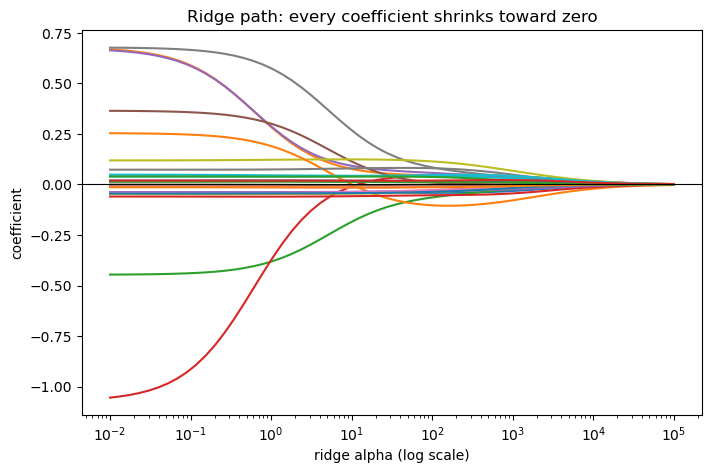

In [13]:
scaler = StandardScaler().fit(val_train[features])
Xtr = scaler.transform(val_train[features])
alphas = np.logspace(-2, 5, 60)
path = np.array([Ridge(alpha=a).fit(Xtr, val_train['log_ps']).coef_ for a in alphas])

plt.figure(figsize=(8, 5))
plt.plot(alphas, path)
plt.xscale('log')
plt.axhline(0, color='black', linewidth=0.8)
plt.xlabel('ridge alpha (log scale)')
plt.ylabel('coefficient')
plt.title('Ridge path: every coefficient shrinks toward zero')
plt.show()

Watch the volatility, beta and residual-volatility lines at the left edge: large and of opposite sign, the multicollinearity from Part 2. A little shrinkage pulls them together first. Ridge spreads the credit across correlated features instead of letting them fight.

## When does shrinkage pay? Experiment 1: less data

Train on small random samples of the training set, 20 times each, and score on the same test set.

In [14]:
rows = []
for n in [60, 100, 200, 400, len(val_train)]:
    for seed in range(20):
        sample = val_train.sample(n, random_state=seed)
        sc = StandardScaler().fit(sample[features])
        ols_n = LinearRegression().fit(sc.transform(sample[features]), sample['log_ps'])
        ridge_n = RidgeCV(alphas=np.logspace(-2, 4, 50)).fit(sc.transform(sample[features]), sample['log_ps'])
        rows.append({'n_train': n,
                     'ols_test_r2': r2_score(val_test['log_ps'], ols_n.predict(sc.transform(val_test[features]))),
                     'ridge_test_r2': r2_score(val_test['log_ps'], ridge_n.predict(sc.transform(val_test[features])))})
pd.DataFrame(rows).groupby('n_train').agg(ols_median=('ols_test_r2', 'median'), ols_worst=('ols_test_r2', 'min'),
                                           ridge_median=('ridge_test_r2', 'median'), ridge_worst=('ridge_test_r2', 'min')).round(3)

,ols_median,ols_worst,ridge_median,ridge_worst
n_train,,,,
60,0.072,-1.281,0.170,0.031
100,0.160,0.022,0.201,0.088
200,0.255,0.162,0.235,0.187
400,0.297,0.242,0.281,0.242
1220,0.328,0.328,0.327,0.327


**Reading it.** With 60 training stocks, least squares has a median test R-squared of 0.07, and its worst draw is -1.28, worse than predicting the average for every stock. Ridge's median is 0.17 and its worst is 0.03. At 100 stocks ridge still wins, 0.20 against 0.16. From 200 stocks up, least squares catches up and edges ahead (0.26 against 0.24 at 200, 0.30 against 0.28 at 400), and with all 1,220 they tie at about 0.33.

That is Stein's bargain in practice. Shrinkage costs a little bias and buys a drop in variance, and the trade pays when variance is the bigger problem: when data is scarce relative to the number of coefficients.

## Experiment 2: more features than sense

Add columns of pure random noise, junk features with no relationship to anything, and refit. This is what happens when you search through hundreds of candidate features: some will fit the training data by coincidence.

In [15]:
rng = np.random.default_rng(1)
rows = []
for k in [0, 50, 200, 500, 900]:
    junk = [f'junk_{i}' for i in range(k)]
    tr = pd.concat([val_train, pd.DataFrame(rng.standard_normal((len(val_train), k)), index=val_train.index, columns=junk)], axis=1)
    te = pd.concat([val_test, pd.DataFrame(rng.standard_normal((len(val_test), k)), index=val_test.index, columns=junk)], axis=1)
    cols = features + junk
    sc = StandardScaler().fit(tr[cols])
    o = LinearRegression().fit(sc.transform(tr[cols]), tr['log_ps'])
    r = RidgeCV(alphas=np.logspace(-2, 5, 60)).fit(sc.transform(tr[cols]), tr['log_ps'])
    l = LassoCV(cv=5, random_state=0, max_iter=5000).fit(sc.transform(tr[cols]), tr['log_ps'])
    rows.append({'junk_features': k,
                 'ols_train_r2': r2_score(tr['log_ps'], o.predict(sc.transform(tr[cols]))),
                 'ols_test_r2': r2_score(te['log_ps'], o.predict(sc.transform(te[cols]))),
                 'ridge_test_r2': r2_score(te['log_ps'], r.predict(sc.transform(te[cols]))),
                 'lasso_test_r2': r2_score(te['log_ps'], l.predict(sc.transform(te[cols]))),
                 'junk_kept_by_lasso': sum(1 for c, w in zip(cols, l.coef_) if c.startswith('junk') and w != 0)})
pd.DataFrame(rows).round(3)

,junk_features,ols_train_r2,ols_test_r2,ridge_test_r2,lasso_test_r2,junk_kept_by_lasso
0,0,0.425,0.328,0.327,0.326,0
1,50,0.450,0.326,0.325,0.297,18
2,200,0.500,0.271,0.236,0.274,22
3,500,0.669,0.096,0.199,0.260,26
4,900,0.865,-0.876,0.157,0.258,21


**Reading it.** Least squares falls for every coincidence. With 900 junk columns its training R-squared climbs to 0.87 while its test R-squared falls to -0.88: it memorized noise. Ridge holds at 0.16. Lasso holds at 0.26, because it can set coefficients to exactly zero; it kept only 21 of the 900. Ridge shrinks the real features along with the junk, so at 200 junk columns it actually trails least squares (0.24 against 0.27); lasso leads from 200 up.

Notice that lasso still kept about 20 junk features at every size. Search through hundreds of candidates and some noise will always look like signal. That is the random-walk reading in data form: more dimensions, more coincidences.

# Part 4: How much of last year's returns can we explain?

Same machinery, the Week 3 target: the 1-year total return, clipped to -100..300 so the 16x moonshots do not steer the line. First with every factor, then without momentum and long-term reversal, the two factors built from past returns.

In [16]:
ret = df.dropna(subset=['total_return_1y']).copy()
ret['return_clipped'] = ret['total_return_1y'].clip(-100, 300)
ret_train, ret_test = train_test_split(ret, test_size=0.2, random_state=5)
no_past_returns = [c for c in mac3_names if c not in ['port_mac3_momentum', 'port_mac3_long_term_reversal']]
for label, cols in [('all factors + sectors (leaky)', mac3_names + sector_names),
                    ('no momentum, no reversal', no_past_returns + sector_names)]:
    tr, te = r2_train_test(cols, ret_train, ret_test, 'return_clipped')
    print(f'{label:32s} train R2 {tr:.3f} | test R2 {te:.3f}')

cols = no_past_returns + sector_names + ['TgtVariable']
ret_ols = sm.OLS(ret_train['return_clipped'], sm.add_constant(ret_train[cols].astype(float))).fit()
print(f"\nAI flag on last year's return: {ret_ols.params['TgtVariable']:.1f} points, t = {ret_ols.tvalues['TgtVariable']:.2f}, p = {ret_ols.pvalues['TgtVariable']:.3f}")
print(f"raw average return: AI {ret.loc[ret.TgtVariable == 1, 'return_clipped'].mean():.1f}%, others {ret.loc[ret.TgtVariable == 0, 'return_clipped'].mean():.1f}%")

all factors + sectors (leaky)    train R2 0.831 | test R2 0.845
no momentum, no reversal         train R2 0.253 | test R2 0.139

AI flag on last year's return: 24.7 points, t = 2.77, p = 0.006
raw average return: AI 69.4%, others 21.9%


**Reading it.** With momentum, test R-squared is 0.845: Week 3's leakage, since momentum is close to a restatement of last year's return. Without the two return-based factors it falls to 0.139, and the gap between train (0.253) and test says even that is partly fitted noise.

Keep Week 3's caveat about the direction of time. These exposures are measured today, after the returns happened, and volatility and beta are computed partly from the same year's prices. This is description, not prediction. A real forecast needs features measured before the returns and a test set that sits later in time, which is Week 8.

**Did AI stocks win?** Yes, by a lot. Raw, AI stocks returned 69 percent against 22 for the rest. Holding sector and every factor except momentum fixed, the AI flag is still worth about 25 points (t = 2.77, p = 0.006). Last year the market paid for the AI story itself, beyond beta, volatility and sector. One year, one draw: that is a description of 2025-26, not a law.

# Part 6: Linear regression in PyTorch

Last week logistic regression was one neuron with a sigmoid and a cross-entropy loss. Linear regression is the same neuron with no sigmoid and a **squared-error loss** (`MSELoss`). Train it with Adam on the valuation problem and compare with scikit-learn, which solves the same problem in closed form.

In [17]:
import torch
import torch.nn as nn

torch.manual_seed(0)
sc = StandardScaler().fit(val_train[features])
Xt = torch.tensor(sc.transform(val_train[features]), dtype=torch.float32)
yt = torch.tensor(val_train['log_ps'].values, dtype=torch.float32)
neuron = nn.Linear(len(features), 1)
opt = torch.optim.Adam(neuron.parameters(), lr=0.01)
loss_fn = nn.MSELoss()
for epoch in range(2000):
    opt.zero_grad()
    loss = loss_fn(neuron(Xt).squeeze(1), yt)
    loss.backward()
    opt.step()

with torch.no_grad():
    torch_pred = neuron(torch.tensor(sc.transform(val_test[features]), dtype=torch.float32)).squeeze(1).numpy()
sk = LinearRegression().fit(sc.transform(val_train[features]), val_train['log_ps'])
print(f'test R2: PyTorch {r2_score(val_test["log_ps"], torch_pred):.4f} | scikit-learn {r2_score(val_test["log_ps"], sk.predict(sc.transform(val_test[features]))):.4f}')
print(f'largest gap between the two sets of coefficients: {np.abs(neuron.weight.detach().numpy()[0] - sk.coef_).max():.4f}')

test R2: PyTorch 0.3277 | scikit-learn 0.3278
largest gap between the two sets of coefficients: 0.3781


**Reading it.** Test R-squared 0.3277 from PyTorch against 0.3278 from scikit-learn: the same model, solved two ways. Yet the coefficients differ by as much as 0.38. That is Part 2's multicollinearity again. Volatility, beta and residual volatility can trade weight among themselves without changing a single prediction, so gradient descent and the closed-form solution settle on different splits. Predictions are trustworthy; those three coefficients are not.

# Part 7: Random walks and spurious regression

Back to the first reading. Simulate 21 random walks: each day, each one steps up or down by a random amount. They are independent by construction; nothing explains anything. Regress walk 0 on the other 20 over the first 250 days, then use that fit on the next 250.

levels:  R2 first 250 days 0.949 | next 250 days -12.244
changes: R2 first 250 days 0.050 | next 249 days -0.108


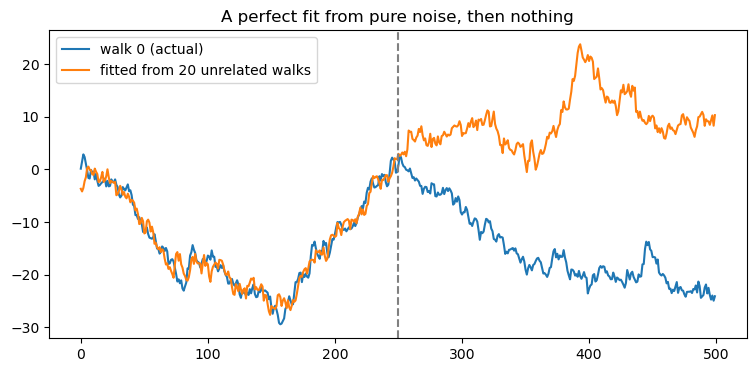

In [18]:
rng = np.random.default_rng(0)
walks = rng.standard_normal((500, 21)).cumsum(axis=0)
y_walk, X_walk = walks[:, 0], walks[:, 1:]

fit = LinearRegression().fit(X_walk[:250], y_walk[:250])
print(f'levels:  R2 first 250 days {r2_score(y_walk[:250], fit.predict(X_walk[:250])):.3f} | '
      f'next 250 days {r2_score(y_walk[250:], fit.predict(X_walk[250:])):.3f}')

steps = np.diff(walks, axis=0)
fit_steps = LinearRegression().fit(steps[:250, 1:], steps[:250, 0])
print(f'changes: R2 first 250 days {r2_score(steps[:250, 0], fit_steps.predict(steps[:250, 1:])):.3f} | '
      f'next 249 days {r2_score(steps[250:, 0], fit_steps.predict(steps[250:, 1:])):.3f}')

plt.figure(figsize=(9, 4))
plt.plot(y_walk, label='walk 0 (actual)')
plt.plot(np.r_[fit.predict(X_walk[:250]), fit.predict(X_walk[250:])], label='fitted from 20 unrelated walks')
plt.axvline(250, color='grey', linestyle='--')
plt.legend()
plt.title('A perfect fit from pure noise, then nothing')
plt.show()

**Reading it.** Twenty unrelated random walks explain the twenty-first with an R-squared of 0.949 over the first 250 days. Use that fit on the next 250 days and R-squared is -12.2: its squared error is about 13 times that of simply guessing the average. Anything that wanders can be lined up against other things that wander, so trending series always look related.

Regress the daily changes instead and the illusion disappears: in-sample R-squared 0.05, out-of-sample -0.11, the honest answer that nothing predicts walk 0. Next week's pairs trade regresses one stock's price on another's. Prices behave much like random walks, so a high R-squared there proves nothing by itself; a pair is tradeable only if the residual keeps coming back to zero, and that is what stat arb checks.

## Reflection questions

0. The linear probability model predicted probabilities below 0 and above 1. Why is that a problem even when its AUC is good?
1. Part 1's slope is about 0.57. In plain words, what does one extra unit of MAC3 beta exposure mean for a stock's measured beta?
2. Health Care's sector coefficient is positive and Consumer Staples' is negative. Translate each into a statement about price per dollar of sales, compared with Communication Services.
3. The volatility coefficient is large and negative, beta's is large and positive. Why can you not conclude that the market pays less for volatile stocks? What would you report instead?
4. Lasso kept about 20 junk features out of 900. Is that a failure of lasso, or a fact about searching through many features? Connect your answer to the random-walk reading.
5. Stein's paradox says shrinkage helps when you estimate three or more things. Our ridge result says it helps most with little data. Reconcile the two.
6. Next week's pairs trade regresses one stock's price on another's. Using Part 7, name the trap, and say what you would regress instead or what you would check first.